# Global Baseline Pricing Model — CA & US

This notebook trains one **global transaction-level ASP model per country**, without splitting by product family. It uses a chronological train/validation/test split and compares:

- weighted median benchmark;
- Ridge linear regression;
- Random Forest;
- CatBoost with RMSE, MAE, Huber, and Quantile losses.

The prediction target is `asp`. To prevent target leakage, fields algebraically derived from revenue/ASP (`revenue`, `margin`, `tax`, and invoice revenue) are excluded. `cost_per_unit` is retained because it is a commercially meaningful pricing input; remove it if cost is not known at scoring time.

**Model-selection rule:** lowest validation weighted MAE, with weighted RMSE and WAPE as secondary diagnostics. The untouched final 15% of dates is used once for the reported test result.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / 'Top 30 Product for US-CA').exists():
    NOTEBOOK_DIR = Path('baseline model_Brynn')
DATA_DIR = NOTEBOOK_DIR / 'Top 30 Product for US-CA'
ARTIFACT_DIR = NOTEBOOK_DIR / 'artifacts'
ARTIFACT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

FILES = {
    'CA': DATA_DIR / 'CA_selected_top30_transactions.csv',
    'US': DATA_DIR / 'US_selected_top30_transactions.csv',
}
FILES

Matplotlib is building the font cache; this may take a moment.


{'CA': PosixPath('/Users/brynnzhang/Desktop/Lenovo/baseline model_Brynn/Top 30 Product for US-CA/CA_selected_top30_transactions.csv'),
 'US': PosixPath('/Users/brynnzhang/Desktop/Lenovo/baseline model_Brynn/Top 30 Product for US-CA/US_selected_top30_transactions.csv')}

## 1. Data preparation and leakage control

The sample weight is:

`weight = clip(sqrt(order_units), 1, 5)`

This gives larger orders more influence while preventing a few unusually large orders from dominating training. It is a modeling weight—not a coefficient applied to the final predicted ASP.

In [2]:
TARGET = 'asp'
CATEGORICAL_FEATURES = [
    'product_id', 'product_line', 'product_model', 'segment', 'product_type',
    'sales_channel', 'state', 'document_category', 'order_status',
]
NUMERIC_FEATURES = [
    'order_units', 'cost_per_unit', 'year', 'month', 'quarter',
    'day_of_week', 'days_since_start',
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

LEAKAGE_COLUMNS = [
    'revenue', 'invoice_revenue_country_currency', 'margin', 'tax',
    'price_tier', 'source_file', 'quarter_fiscal', 'month_fiscal',
]

def load_country(path, country):
    df = pd.read_csv(path, low_memory=False)
    df['pricing_date'] = pd.to_datetime(df['pricing_date'], errors='coerce')
    df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
    df['order_units'] = pd.to_numeric(df['order_units'], errors='coerce')
    df['cost'] = pd.to_numeric(df['cost'], errors='coerce')
    df = df.loc[
        df['pricing_date'].notna() & df[TARGET].notna() &
        np.isfinite(df[TARGET]) & (df[TARGET] > 0) &
        df['order_units'].notna() & (df['order_units'] > 0)
    ].copy()
    df['cost_per_unit'] = df['cost'] / df['order_units']
    df['year'] = df['pricing_date'].dt.year
    df['month'] = df['pricing_date'].dt.month
    df['quarter'] = df['pricing_date'].dt.quarter
    df['day_of_week'] = df['pricing_date'].dt.dayofweek
    df['days_since_start'] = (df['pricing_date'] - df['pricing_date'].min()).dt.days
    for c in CATEGORICAL_FEATURES:
        df[c] = df[c].astype('string').fillna('<missing>').astype(str)
    for c in NUMERIC_FEATURES:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df['sample_weight'] = np.sqrt(df['order_units']).clip(1, 5)
    df['country_model'] = country
    return df.sort_values('pricing_date').reset_index(drop=True)

def chronological_split(df, train_share=.70, validation_share=.15):
    dates = np.array(sorted(df['pricing_date'].dropna().unique()))
    train_end = pd.Timestamp(dates[max(0, int(len(dates) * train_share) - 1)])
    valid_end = pd.Timestamp(dates[max(0, int(len(dates) * (train_share + validation_share)) - 1)])
    train = df[df['pricing_date'] <= train_end].copy()
    valid = df[(df['pricing_date'] > train_end) & (df['pricing_date'] <= valid_end)].copy()
    test = df[df['pricing_date'] > valid_end].copy()
    return train, valid, test, train_end, valid_end

datasets = {country: load_country(path, country) for country, path in FILES.items()}
summary = pd.DataFrame([
    {'country': c, 'rows': len(d), 'products': d.product_id.nunique(),
     'start': d.pricing_date.min().date(), 'end': d.pricing_date.max().date(),
     'median_asp': d.asp.median()}
    for c, d in datasets.items()
])
summary

,country,rows,products,start,end,median_asp
0,CA,17732,30,2023-06-14,2026-08-29,"1,004.1100"
1,US,89086,30,2023-04-04,2026-08-29,"1,189.1500"


In [3]:
split_rows = []
splits = {}
for country, df in datasets.items():
    train, valid, test, train_end, valid_end = chronological_split(df)
    splits[country] = (train, valid, test)
    for name, part in [('train', train), ('validation', valid), ('test', test)]:
        split_rows.append({
            'country': country, 'split': name, 'rows': len(part),
            'start': part.pricing_date.min().date(), 'end': part.pricing_date.max().date(),
        })
pd.DataFrame(split_rows)

,country,split,rows,start,end
0,CA,train,8552,2023-06-14,2025-10-12
1,CA,validation,4349,2025-10-13,2026-03-08
2,CA,test,4831,2026-03-09,2026-08-29
3,US,train,36910,2023-04-04,2025-08-13
4,US,validation,26157,2025-08-14,2026-02-07
5,US,test,26019,2026-02-08,2026-08-29


## 2. Models, losses, and metrics

For model selection, weighted MAE is the primary loss because realized ASP contains outliers. RMSE is included to show sensitivity to large misses, and WAPE gives an easily interpretable percentage-like error. CatBoost is tested with four objectives; MAE and Huber are more robust than squared error.

In [4]:
def metrics(y, pred, w):
    y, pred, w = map(np.asarray, (y, pred, w))
    return {
        'weighted_MAE': np.average(np.abs(y - pred), weights=w),
        'weighted_RMSE': np.sqrt(np.average((y - pred) ** 2, weights=w)),
        'weighted_WAPE': np.sum(w * np.abs(y - pred)) / np.sum(w * np.abs(y)),
        'unweighted_MAE': mean_absolute_error(y, pred),
        'R2': 1 - np.sum(w * (y - pred) ** 2) / np.sum(w * (y - np.average(y, weights=w)) ** 2),
    }

def make_ridge():
    prep = ColumnTransformer([
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=5)),
        ]), CATEGORICAL_FEATURES),
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), NUMERIC_FEATURES),
    ])
    return Pipeline([('prep', prep), ('model', Ridge(alpha=10.0))])

def make_rf():
    prep = ColumnTransformer([
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), CATEGORICAL_FEATURES),
        ('num', SimpleImputer(strategy='median'), NUMERIC_FEATURES),
    ])
    model = RandomForestRegressor(
        n_estimators=180, max_depth=18, min_samples_leaf=8,
        max_features=.75, n_jobs=-1, random_state=RANDOM_STATE,
    )
    return Pipeline([('prep', prep), ('model', model)])

CATBOOST_LOSSES = {
    'CatBoost_RMSE': 'RMSE',
    'CatBoost_MAE': 'MAE',
    'CatBoost_Huber': 'Huber:delta=100',
    'CatBoost_Quantile': 'Quantile:alpha=0.5',
}

def fit_and_compare(country, train, valid):
    Xtr, ytr, wtr = train[FEATURES], train[TARGET], train['sample_weight']
    Xva, yva, wva = valid[FEATURES], valid[TARGET], valid['sample_weight']
    fitted, rows = {}, []

    dummy = DummyRegressor(strategy='median').fit(Xtr, ytr, sample_weight=wtr)
    fitted['Weighted_Median'] = dummy
    rows.append({'country': country, 'model': 'Weighted_Median', **metrics(yva, dummy.predict(Xva), wva)})

    ridge = make_ridge().fit(Xtr, ytr, model__sample_weight=wtr)
    fitted['Ridge'] = ridge
    rows.append({'country': country, 'model': 'Ridge', **metrics(yva, ridge.predict(Xva), wva)})

    rf = make_rf().fit(Xtr, ytr, model__sample_weight=wtr)
    fitted['Random_Forest'] = rf
    rows.append({'country': country, 'model': 'Random_Forest', **metrics(yva, rf.predict(Xva), wva)})

    cat_idx = [FEATURES.index(c) for c in CATEGORICAL_FEATURES]
    for name, loss in CATBOOST_LOSSES.items():
        model = CatBoostRegressor(
            loss_function=loss, iterations=450, depth=8, learning_rate=.06,
            l2_leaf_reg=5, random_seed=RANDOM_STATE, verbose=False,
            allow_writing_files=False, thread_count=-1,
        )
        model.fit(Xtr, ytr, cat_features=cat_idx, sample_weight=wtr,
                  eval_set=(Xva, yva), early_stopping_rounds=60, verbose=False)
        fitted[name] = model
        rows.append({'country': country, 'model': name, **metrics(yva, model.predict(Xva), wva)})
    return fitted, pd.DataFrame(rows)

all_models, validation_tables = {}, []
for country, (train, valid, test) in splits.items():
    fitted, table = fit_and_compare(country, train, valid)
    all_models[country] = fitted
    validation_tables.append(table)

validation_results = pd.concat(validation_tables, ignore_index=True).sort_values(['country', 'weighted_MAE'])
validation_results.to_csv(ARTIFACT_DIR / 'validation_model_comparison.csv', index=False)
validation_results

,country,model,weighted_MAE,weighted_RMSE,weighted_WAPE,unweighted_MAE,R2
3,CA,CatBoost_RMSE,157.4096,258.0425,0.1353,161.5317,0.8356
4,CA,CatBoost_MAE,166.3404,271.5085,0.1430,170.0360,0.8180
6,CA,CatBoost_Quantile,166.3404,271.5085,0.1430,170.0360,0.8180
2,CA,Random_Forest,186.5109,289.9298,0.1603,190.1419,0.7925
1,CA,Ridge,190.0189,262.5042,0.1633,193.5054,0.8299
0,CA,Weighted_Median,635.7789,782.7627,0.5465,652.7675,-0.5126
5,CA,CatBoost_Huber,900.0218,"1,070.5447",0.7737,895.0110,-1.8292
9,US,Random_Forest,189.6652,306.1518,0.1493,193.6873,0.8273
11,US,CatBoost_MAE,200.3398,308.4395,0.1577,204.6844,0.8247
13,US,CatBoost_Quantile,200.3398,308.4395,0.1577,204.6844,0.8247


## 3. Select the winner and evaluate the untouched test period

Selection happens strictly on validation weighted MAE. The chosen model is then refit on train + validation and evaluated on the final chronological test window. This avoids choosing a model based on test results.

In [5]:
def refit_model(name, train_valid):
    X, y, w = train_valid[FEATURES], train_valid[TARGET], train_valid['sample_weight']
    if name == 'Weighted_Median':
        return DummyRegressor(strategy='median').fit(X, y, sample_weight=w)
    if name == 'Ridge':
        return make_ridge().fit(X, y, model__sample_weight=w)
    if name == 'Random_Forest':
        return make_rf().fit(X, y, model__sample_weight=w)
    loss = CATBOOST_LOSSES[name]
    cat_idx = [FEATURES.index(c) for c in CATEGORICAL_FEATURES]
    return CatBoostRegressor(
        loss_function=loss, iterations=450, depth=8, learning_rate=.06,
        l2_leaf_reg=5, random_seed=RANDOM_STATE, verbose=False,
        allow_writing_files=False, thread_count=-1,
    ).fit(X, y, cat_features=cat_idx, sample_weight=w, verbose=False)

final_models, test_rows, predictions, importance_rows = {}, [], [], []
for country, (train, valid, test) in splits.items():
    winner = validation_results.query('country == @country').iloc[0]['model']
    train_valid = pd.concat([train, valid], ignore_index=True)
    model = refit_model(winner, train_valid)
    final_models[country] = model
    pred = model.predict(test[FEATURES])
    test_rows.append({'country': country, 'selected_model': winner, **metrics(test[TARGET], pred, test['sample_weight'])})
    pred_df = test[['pricing_date', 'product_id', 'order_units', TARGET, 'sample_weight']].copy()
    pred_df['prediction'] = pred
    pred_df['country'] = country
    predictions.append(pred_df)

    if winner.startswith('CatBoost'):
        imp = model.get_feature_importance()
        for feature, value in zip(FEATURES, imp):
            importance_rows.append({'country': country, 'feature': feature, 'importance_pct': value})
    elif winner == 'Random_Forest':
        imp = model.named_steps['model'].feature_importances_
        for feature, value in zip(CATEGORICAL_FEATURES + NUMERIC_FEATURES, imp * 100):
            importance_rows.append({'country': country, 'feature': feature, 'importance_pct': value})

test_results = pd.DataFrame(test_rows)
prediction_df = pd.concat(predictions, ignore_index=True)
feature_importance = pd.DataFrame(importance_rows).sort_values(['country', 'importance_pct'], ascending=[True, False])

test_results.to_csv(ARTIFACT_DIR / 'final_test_metrics.csv', index=False)
prediction_df.to_csv(ARTIFACT_DIR / 'test_predictions.csv', index=False)
feature_importance.to_csv(ARTIFACT_DIR / 'final_feature_importance.csv', index=False)
test_results

,country,selected_model,weighted_MAE,weighted_RMSE,weighted_WAPE,unweighted_MAE,R2
0,CA,CatBoost_RMSE,182.2280,298.0206,0.1408,185.7149,0.7138
1,US,Random_Forest,216.2154,321.8600,0.1637,219.5431,0.7417


In [6]:
feature_importance.groupby('country', group_keys=False).head(12)

,country,feature,importance_pct
10,CA,cost_per_unit,58.5723
15,CA,days_since_start,9.9976
4,CA,product_type,9.6381
1,CA,product_line,8.8975
5,CA,sales_channel,2.5858
12,CA,month,2.4951
2,CA,product_model,1.9567
7,CA,document_category,1.4977
0,CA,product_id,1.2298
14,CA,day_of_week,1.0314


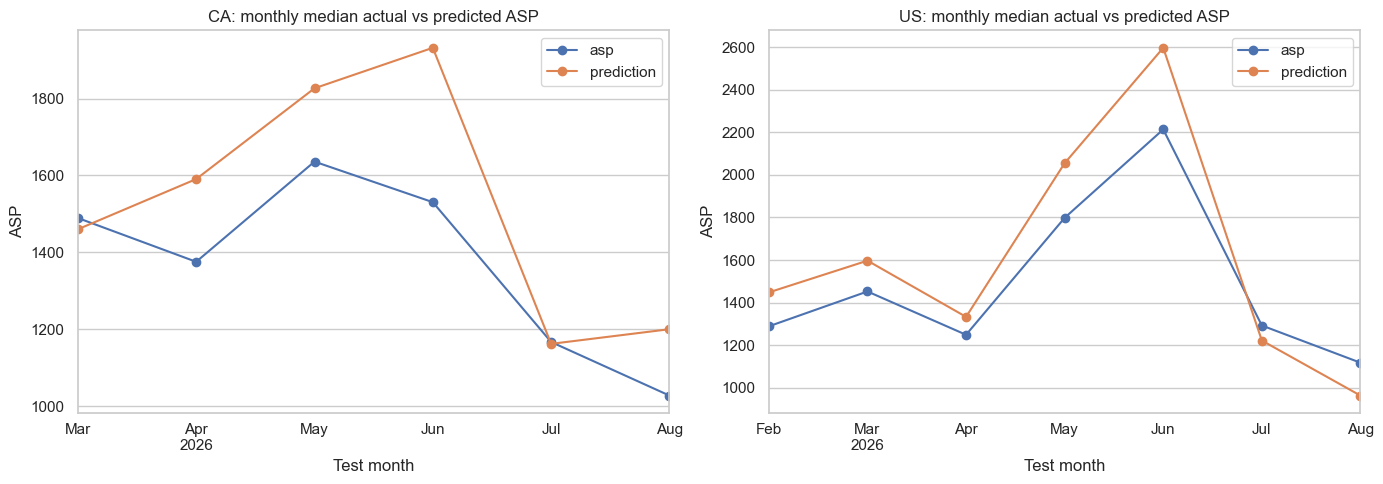

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, country in zip(axes, ['CA', 'US']):
    p = prediction_df.query('country == @country').sort_values('pricing_date')
    monthly = p.set_index('pricing_date')[[TARGET, 'prediction']].resample('MS').median()
    monthly.plot(ax=ax, marker='o')
    ax.set_title(f'{country}: monthly median actual vs predicted ASP')
    ax.set_ylabel('ASP')
    ax.set_xlabel('Test month')
plt.tight_layout()
plt.show()

## 4. Stability checks by product

The table below checks whether a good global average hides poor performance for individual products. Products with very few test observations should be treated cautiously.

In [8]:
group_rows = []
for (country, product), g in prediction_df.groupby(['country', 'product_id']):
    m = metrics(g[TARGET], g['prediction'], g['sample_weight'])
    group_rows.append({'country': country, 'product_id': product, 'rows': len(g), **m})
product_metrics = pd.DataFrame(group_rows).sort_values(['country', 'weighted_MAE'], ascending=[True, False])
product_metrics.to_csv(ARTIFACT_DIR / 'test_metrics_by_product.csv', index=False)
product_metrics.groupby('country', group_keys=False).head(10)

,country,product_id,rows,weighted_MAE,weighted_RMSE,weighted_WAPE,unweighted_MAE,R2
5,CA,10TBMCG2LC,167,692.2488,"1,055.4295",0.2898,698.4830,0.1978
20,CA,74VSTVW6PG,97,294.5696,437.4193,0.1900,303.9203,0.2918
27,CA,99CECOV2XP,107,278.1930,378.1925,0.1804,284.3097,0.3497
13,CA,36N5074JFA,343,265.8094,286.9343,0.2975,267.5340,-4.5598
24,CA,95M59825ZR,75,265.3760,344.7764,0.1419,265.1480,-0.4987
8,CA,16T0MJI6WJ,177,222.3210,323.9325,0.1595,234.5501,0.7031
2,CA,03DF114WYO,213,219.3765,300.2316,0.1268,216.7263,-0.3960
15,CA,37NELHX9FG,138,203.4164,303.8273,0.1088,203.9911,0.5142
29,CA,99R3052SJU,137,191.3463,270.6903,0.1134,194.3363,0.0713
10,CA,19Y55740YG,267,173.1004,185.6510,0.1994,175.2844,-4.3706


## 5. Final conclusion

The next cell prints a reproducible summary. Here, **weight** has two meanings:

1. **Training sample weight:** `clip(sqrt(order_units), 1, 5)`; this is the recommended global weighting rule.
2. **Feature weight:** the selected tree model's normalized importance percentages; these describe predictive contribution, not a causal price formula.

If an auditable coefficient formula is mandatory, use the Ridge result as the interpretable fallback. For production prediction, use the validation-selected winner shown below.

In [9]:
conclusion = {}
for _, row in test_results.iterrows():
    country = row['country']
    top = feature_importance.query('country == @country').head(8)
    conclusion[country] = {
        'recommended_model': row['selected_model'],
        'test_weighted_MAE': round(row['weighted_MAE'], 2),
        'test_weighted_RMSE': round(row['weighted_RMSE'], 2),
        'test_weighted_WAPE': round(row['weighted_WAPE'], 4),
        'test_R2': round(row['R2'], 4),
        'sample_weight_formula': 'clip(sqrt(order_units), 1, 5)',
        'top_feature_weights_pct': {r.feature: round(r.importance_pct, 2) for r in top.itertuples()},
    }
print(json.dumps(conclusion, indent=2))
with open(ARTIFACT_DIR / 'model_conclusion.json', 'w') as f:
    json.dump(conclusion, f, indent=2)
conclusion

{
  "CA": {
    "recommended_model": "CatBoost_RMSE",
    "test_weighted_MAE": 182.23,
    "test_weighted_RMSE": 298.02,
    "test_weighted_WAPE": 0.1408,
    "test_R2": 0.7138,
    "sample_weight_formula": "clip(sqrt(order_units), 1, 5)",
    "top_feature_weights_pct": {
      "cost_per_unit": 58.57,
      "days_since_start": 10.0,
      "product_type": 9.64,
      "product_line": 8.9,
      "sales_channel": 2.59,
      "month": 2.5,
      "product_model": 1.96,
      "document_category": 1.5
    }
  },
  "US": {
    "recommended_model": "Random_Forest",
    "test_weighted_MAE": 216.22,
    "test_weighted_RMSE": 321.86,
    "test_weighted_WAPE": 0.1637,
    "test_R2": 0.7417,
    "sample_weight_formula": "clip(sqrt(order_units), 1, 5)",
    "top_feature_weights_pct": {
      "cost_per_unit": 73.5,
      "product_line": 13.17,
      "product_model": 3.97,
      "product_type": 2.56,
      "days_since_start": 2.06,
      "sales_channel": 1.59,
      "product_id": 0.98,
      "month": 0.

{'CA': {'recommended_model': 'CatBoost_RMSE',
  'test_weighted_MAE': 182.23,
  'test_weighted_RMSE': 298.02,
  'test_weighted_WAPE': 0.1408,
  'test_R2': 0.7138,
  'sample_weight_formula': 'clip(sqrt(order_units), 1, 5)',
  'top_feature_weights_pct': {'cost_per_unit': 58.57,
   'days_since_start': 10.0,
   'product_type': 9.64,
   'product_line': 8.9,
   'sales_channel': 2.59,
   'month': 2.5,
   'product_model': 1.96,
   'document_category': 1.5}},
 'US': {'recommended_model': 'Random_Forest',
  'test_weighted_MAE': 216.22,
  'test_weighted_RMSE': 321.86,
  'test_weighted_WAPE': 0.1637,
  'test_R2': 0.7417,
  'sample_weight_formula': 'clip(sqrt(order_units), 1, 5)',
  'top_feature_weights_pct': {'cost_per_unit': 73.5,
   'product_line': 13.17,
   'product_model': 3.97,
   'product_type': 2.56,
   'days_since_start': 2.06,
   'sales_channel': 1.59,
   'product_id': 0.98,
   'month': 0.67}}}

### Important limitations

- This is a predictive realized-price baseline, **not a causal price-elasticity model**. The data contains completed transactions but no rejected quotes or randomized price changes.
- Product/customer/channel mix can shift over time; monitor weighted MAE and WAPE by country and product monthly.
- Feature importance does not tell us how much ASP will change if a feature is manipulated.
- Before deployment, confirm that `cost`, units, channel, state, and product attributes are available at the time a price is scored.